In [10]:
import fitsio
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

from astropy.wcs import WCS
import sep

from kl_tools.intensity import build_intensity_map
from kl_tools.parameters import ImagePars
from kl_tools.kross.data import get_kross_obj_data
from kl_tools.interloper_mask import create_interloper_mask


In [11]:
def load_jwst_data(ext):
    '''
    Loads and preprocesses JWST imaging data for a given KROSS object ID.

    Args:
        ext (int): The JWST fits file extension number .

    Returns:
        tuple: A tuple containing:
            - jwst_image (np.ndarray): The original JWST image.
            - image_pars (ImagePars): An ImagePars object with WCS info.
            - initial_params (dict): A dictionary of initial guesses for the fit.
            - interloper_mask (np.ndarray): A boolean mask of interloping sources.
    '''
    print(f"Loading JWST data for EXT {ext}...")
    #obj_data = get_kross_obj_data(ext)
    jwst_image = fitsio.read("./data_compile_short_GDS_ID195280_emlonly.fits",ext)
    jwst_hdr = fitsio.read_header("./data_compile_short_GDS_ID195280_emlonly.fits",ext)
    image_wcs = WCS(jwst_hdr)

    # Estimate background for masking
    bkg = sep.Background(jwst_image)
    bkg_std = bkg.globalrms

    # Create a mask for foreground objects
    interloper_mask = create_interloper_mask(
        jwst_image, bkg_std, threshold=1.5, gaussian_sigma=5.0
    )
    print(f"Masked {np.sum(interloper_mask)} pixels as interlopers.")

    # Setup ImagePars
    Nrow, Ncol = jwst_image.shape
    image_pars = ImagePars((Ncol, Nrow), wcs=image_wcs)

    # Get initial parameter guesses from the central object
    objects = sep.extract(jwst_image, 1.5, err=bkg_std)
    
    # Find the object closest to the center of the image
    im_center_y, im_center_x = np.array(jwst_image.shape) / 2.0
    distances_sq = (objects['x'] - im_center_x)**2 + (objects['y'] - im_center_y)**2
    central_obj_index = np.argmin(distances_sq)
    central_obj = objects[central_obj_index]
    
    # Use geometric mean of semi-major/minor axes for HLR guess
    # and convert from pixels to arcseconds
    hlr_guess_pixels = np.sqrt(central_obj['a'] * central_obj['b'])
    hlr_guess_arcsec = hlr_guess_pixels * image_pars.pixel_scale

    initial_params = {
        'flux': central_obj['flux'],
        'hlr': hlr_guess_arcsec,
        'x0_pix': central_obj['x'],
        'y0_pix': central_obj['y'],
    }

    return jwst_image, image_pars, initial_params, interloper_mask

Loading JWST data for EXT 4...
Masked 0 pixels as interlopers.


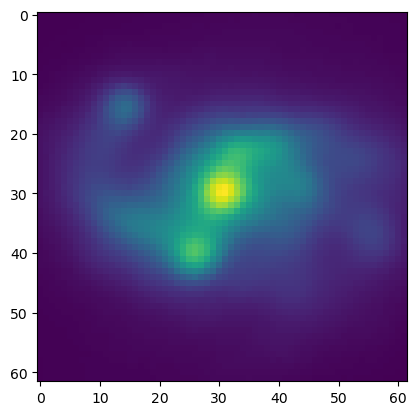

In [26]:
data = load_jwst_data(4)
plt.imshow(data[0])
plt.show()